# DC4 simulated-background time stability

This notebook tests one question: after excluding SAA intervals and normalizing away the total event count, is the simulated DC4 background shape in $(E_m, \phi, \psi, \chi)$ stable with time?

Scope boundaries:

- The input is only the simulated DC4 background FITS file.
- No normalizing-flow model is loaded, evaluated, sampled, or trained.
- Histogram bins are diagnostics for this stability check, not a proposed background model.
- Raw counts/rates and independently normalized shapes are examined separately.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Setup

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits

In [3]:
background_path = Path("../data/Total_DC4_BG_3months_unbinned_data_filtered_with_SAAcut_withSAAbck.fits")
orientation_path = Path("../data/DC4_orientation.ori")
assert background_path.exists() and orientation_path.exists()

## 2. Inspect the DC4 event file

The FITS table is inspected directly and memory-mapped because it contains about 169 million rows. Loading it through the COSIpy event class would sort all rows in memory, which is unnecessary for histogram accumulation.

In [4]:
with fits.open(background_path, memmap=True, lazy_load_hdus=True) as file:
    event_count = file[1].header["NAXIS2"]
    columns = [(column.name, column.unit) for column in file[1].columns]
print(f"Events: {event_count:,}")
columns

Events: 168,648,544


[('Energies', 'keV'),
 ('TimeTags', 's'),
 ('Xpointings (glon,glat)', 'rad'),
 ('Ypointings (glon,glat)', 'rad'),
 ('Zpointings (glon,glat)', 'rad'),
 ('Phi', 'rad'),
 ('Chi local', 'rad'),
 ('Psi local', 'rad'),
 ('Distance', 'cm'),
 ('Chi galactic', 'deg'),
 ('Psi galactic', 'deg')]

### Verified event mapping

The table provides `TimeTags`, `Energies`, `Phi`, `Psi local`, and `Chi local`. The installed COSIpy loader interprets `TimeTags` as Unix seconds, uses `Energies` as $E_m$, uses `Phi` as the Compton scattering angle, uses `Chi local` as spacecraft-frame longitude, and converts the stored `Psi local` colatitude to latitude with $\pi/2-\mathrm{Psi\ local}$.

The event table contains neither an SAA flag nor an orbit identifier. Therefore, neither is inferred from the event columns. The SAA selection is taken from the accompanying orientation file instead.

## 3. Reproduce the documented SAA selection

COSIpy's [`cut_SAA_events`](https://github.com/cositools/cosipy/blob/2cc83ad5176338cbacddb2205db2e31b9b7f8b15/cosipy/data_io/UnBinnedData.py#L825-L917) constructs bad intervals from entries with zero livetime in the orientation file. The corresponding [orientation parser](https://github.com/cositools/cosipy/blob/2cc83ad5176338cbacddb2205db2e31b9b7f8b15/cosipy/spacecraftfile/spacecraft_file.py#L395-L499) defines the final `.ori` column as the accumulated livetime up to the following timestamp.

This is the provenance of the selection below; the cut is not inferred from the FITS filename. Events are assigned to half-open orientation intervals $[t_i,t_{i+1})$ and retained only when that interval has positive livetime.

In [5]:
orientation = np.loadtxt(orientation_path, skiprows=1, comments="EN", usecols=range(1, 10))
orientation_times = orientation[:, 0]
livetimes = orientation[:-1, 8]
interval_durations = np.diff(orientation_times)

In [6]:
excluded = livetimes == 0
start_index = np.flatnonzero(excluded & np.r_[True, ~excluded[:-1]])
stop_index = np.flatnonzero(excluded & np.r_[~excluded[1:], True]) + 1
saa_starts, saa_stops = orientation_times[start_index], orientation_times[stop_index]

In [7]:
saa_durations = saa_stops - saa_starts
print(f"Orientation intervals: {len(livetimes):,}; SAA blocks: {len(saa_starts):,}")
print(f"SAA duration [s], min/median/max: {saa_durations.min():.0f}/{np.median(saa_durations):.0f}/{saa_durations.max():.0f}")
print(f"Accepted livetime fraction: {livetimes.sum() / interval_durations.sum():.3f}")

Orientation intervals: 531,997; SAA blocks: 1,300
SAA duration [s], min/median/max: 525/1080/1125
Accepted livetime fraction: 0.825


## 4. Define the temporal comparisons

There is no orbit identifier in either input. Rather than invent orbit boundaries, `time_interval_days` controls the duration of consecutive wall-clock intervals. The default is 7 days. If the observation does not contain an integer number of intervals, the final shorter interval is retained and its actual duration and livetime are reported; no events are removed to make the intervals equal.

A second comparison probes the local time dependence around the documented SAA blocks. Following the diagnostic used in Section 3.6.1 and Figure 3.17 of [Pascal Janowski's thesis](https://cms.zdv.uni-mainz.de/fb08-xenon-physik/wp-content/uploads/sites/107/2026/03/oberlack-group-thesis_2025_MSc_Janowski-Pascal.pdf), events in the first 10 minutes after each SAA block are compared with those in the final 10 minutes before the next block. The thesis analysis used DC3 components; here the same diagnostic is applied directly to the combined DC4 simulated background, without using Pascal's model.

In [8]:
time_interval_days = 7.0
time_step = time_interval_days * 86400
time_edges = np.arange(orientation_times[0], orientation_times[-1], time_step)
time_edges = np.append(time_edges, orientation_times[-1])
number_time_groups = len(time_edges) - 1
group_days = np.diff(time_edges) / 86400
print(f"Time groups: {number_time_groups}; requested duration: {time_interval_days:g} days")
print(f"Actual durations [days]: min={group_days.min():.3f}, max={group_days.max():.3f}")

Time groups: 14; requested duration: 7 days
Actual durations [days]: min=1.361, max=7.000


In [9]:
group_livetime = np.zeros(number_time_groups)
for group in range(number_time_groups):
    overlap = np.maximum(0, np.minimum(orientation_times[1:], time_edges[group + 1]) - np.maximum(orientation_times[:-1], time_edges[group]))
    group_livetime[group] = np.sum(overlap * livetimes / interval_durations)

## 5. Diagnostic CDS histograms

The marginal projections use logarithmic energy bins over the stored 100–10,000 keV range and uniform 3-degree angular bins over their full domains. These choices resolve narrow temporal structure while retaining large counts per bin.

A separate coarse 4D histogram uses 10 energy bins and 6, 6, and 12 angular bins. It is included because stable one-dimensional marginals do not guarantee stable correlations. This coarse table is only a diagnostic contingency table, not $P(E_m,\phi,\psi,\chi)$ and not a proposed model binning.

In [10]:
projection_edges = {
    "Energy": np.geomspace(100, 10_000, 121),
    "Phi": np.linspace(0, np.pi, 61),
    "Psi": np.linspace(0, np.pi, 61),
    "Chi": np.linspace(0, 2 * np.pi, 121),
}
projection_columns = {"Energy": "Energies", "Phi": "Phi", "Psi": "Psi local", "Chi": "Chi local"}

In [11]:
joint_edges = [np.geomspace(100, 10_000, 11), np.linspace(0, np.pi, 7),
               np.linspace(0, np.pi, 7), np.linspace(0, 2 * np.pi, 13)]
joint_shape = tuple(len(edges) - 1 for edges in joint_edges)
print(f"Coarse 4D cells: {np.prod(joint_shape):,}")

Coarse 4D cells: 4,320


In [12]:
group_counts = {name: np.zeros((number_time_groups, len(edges) - 1), dtype=np.int64) for name, edges in projection_edges.items()}
phase_counts = {name: np.zeros((2, len(edges) - 1), dtype=np.int64) for name, edges in projection_edges.items()}
joint_counts = np.zeros((number_time_groups, np.prod(joint_shape)), dtype=np.int64)
events_per_group, events_per_phase = np.zeros(number_time_groups, dtype=np.int64), np.zeros(2, dtype=np.int64)

### One chunked pass through the events

Each raw event is mapped to its orientation interval. Events in zero-livetime intervals are rejected before any histogram is filled. The FITS rows are not assumed to be time ordered.

In [13]:
rejected_events = 0
group_axis_edges = np.arange(number_time_groups + 1) - 0.5
with fits.open(background_path, memmap=True) as file:
    events = file[1].data
    for start in range(0, len(events), 1_000_000):
        chunk = events[start:start + 1_000_000]
        times = np.asarray(chunk["TimeTags"])
        interval = np.searchsorted(orientation_times, times, side="right") - 1
        in_range = (interval >= 0) & (interval < len(livetimes))
        accepted = np.zeros(len(times), dtype=bool)
        accepted[in_range] = livetimes[interval[in_range]] > 0
        rejected_events += np.count_nonzero(~accepted)
        group = np.searchsorted(time_edges, times, side="right") - 1
        keep = accepted & (group >= 0) & (group < number_time_groups)
        kept_group = group[keep]
        events_per_group += np.bincount(kept_group, minlength=number_time_groups)

        previous_exit = np.searchsorted(saa_stops, times, side="right") - 1
        after = accepted & (previous_exit >= 0)
        after[after] &= times[after] - saa_stops[previous_exit[after]] < 600
        next_entry = np.searchsorted(saa_starts, times, side="left")
        before = accepted & (next_entry < len(saa_starts))
        before[before] &= saa_starts[next_entry[before]] - times[before] < 600
        events_per_phase += [np.count_nonzero(after), np.count_nonzero(before)]

        values_by_axis = []
        for name, column in projection_columns.items():
            values = np.asarray(chunk[column])
            values_by_axis.append(values)
            group_counts[name] += np.histogram2d(kept_group, values[keep], bins=(group_axis_edges, projection_edges[name]))[0].astype(np.int64)
            phase_counts[name][0] += np.histogram(values[after], bins=projection_edges[name])[0]
            phase_counts[name][1] += np.histogram(values[before], bins=projection_edges[name])[0]

        joint_bins, joint_ranges = [], []
        for edges, values in zip(joint_edges, values_by_axis):
            kept_values = values[keep]
            joint_ranges.append((kept_values >= edges[0]) & (kept_values <= edges[-1]))
            bins = np.searchsorted(edges, kept_values, side="right") - 1
            joint_bins.append(np.clip(bins, 0, len(edges) - 2))
        valid_joint = np.logical_and.reduce(joint_ranges)
        flat_joint = np.ravel_multi_index(tuple(bins[valid_joint] for bins in joint_bins), joint_shape)
        flat_grouped = kept_group[valid_joint] * joint_counts.shape[1] + flat_joint
        joint_counts += np.bincount(flat_grouped, minlength=joint_counts.size).reshape(joint_counts.shape)

In [14]:
accepted_events = events_per_group.sum()
print(f"Accepted events: {accepted_events:,}; rejected in zero-livetime intervals: {rejected_events:,}")
assert accepted_events + rejected_events == event_count
assert all(counts.sum() == accepted_events for counts in group_counts.values())
assert joint_counts.sum() == accepted_events

Accepted events: 168,648,420; rejected in zero-livetime intervals: 124


## 6. Raw amplitude: counts and rate

This section deliberately does not normalize the events. It describes amplitude changes only; it is not evidence about CDS-shape stability.

In [15]:
amplitude = pd.DataFrame({
    "midpoint_day": ((time_edges[:-1] + time_edges[1:]) / 2 - time_edges[0]) / 86400,
    "livetime_days": group_livetime / 86400,
    "raw_events": events_per_group,
    "rate_per_second": events_per_group / group_livetime,
})
amplitude

,midpoint_day,livetime_days,raw_events,rate_per_second
0,3.500000,5.786285,12530052,25.063362
1,10.500000,5.774132,12726813,25.510514
2,17.500000,5.784722,12781207,25.572643
3,24.500000,5.769792,12767368,25.611057
4,31.500000,5.781250,12813576,25.652805
5,38.500000,5.769618,12797750,25.672775
6,45.500000,5.776736,12822011,25.689750
7,52.500000,5.763889,12810513,25.723922
8,59.500000,5.775347,12834333,25.720622
9,66.500000,5.760069,12815669,25.751339


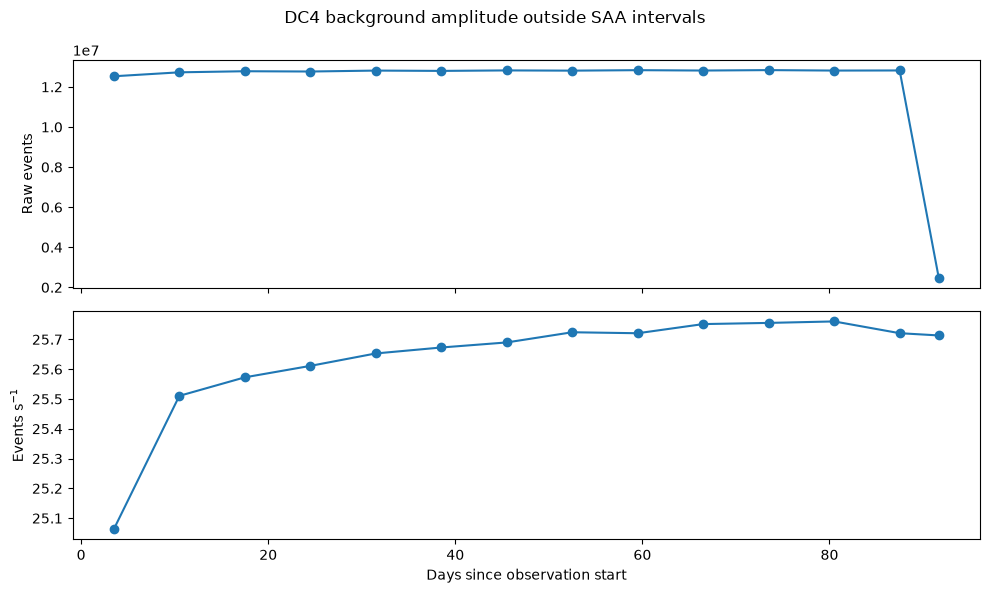

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(amplitude.midpoint_day, amplitude.raw_events, marker="o")
axes[1].plot(amplitude.midpoint_day, amplitude.rate_per_second, marker="o")
axes[0].set_ylabel("Raw events")
axes[1].set(xlabel="Days since observation start", ylabel="Events s$^{-1}$")
fig.suptitle("DC4 background amplitude outside SAA intervals")
fig.tight_layout()

## 7. Independently normalized CDS projections

Every time-group histogram is divided by its own event total and bin width. Consequently, the following plots compare shape, not amplitude.

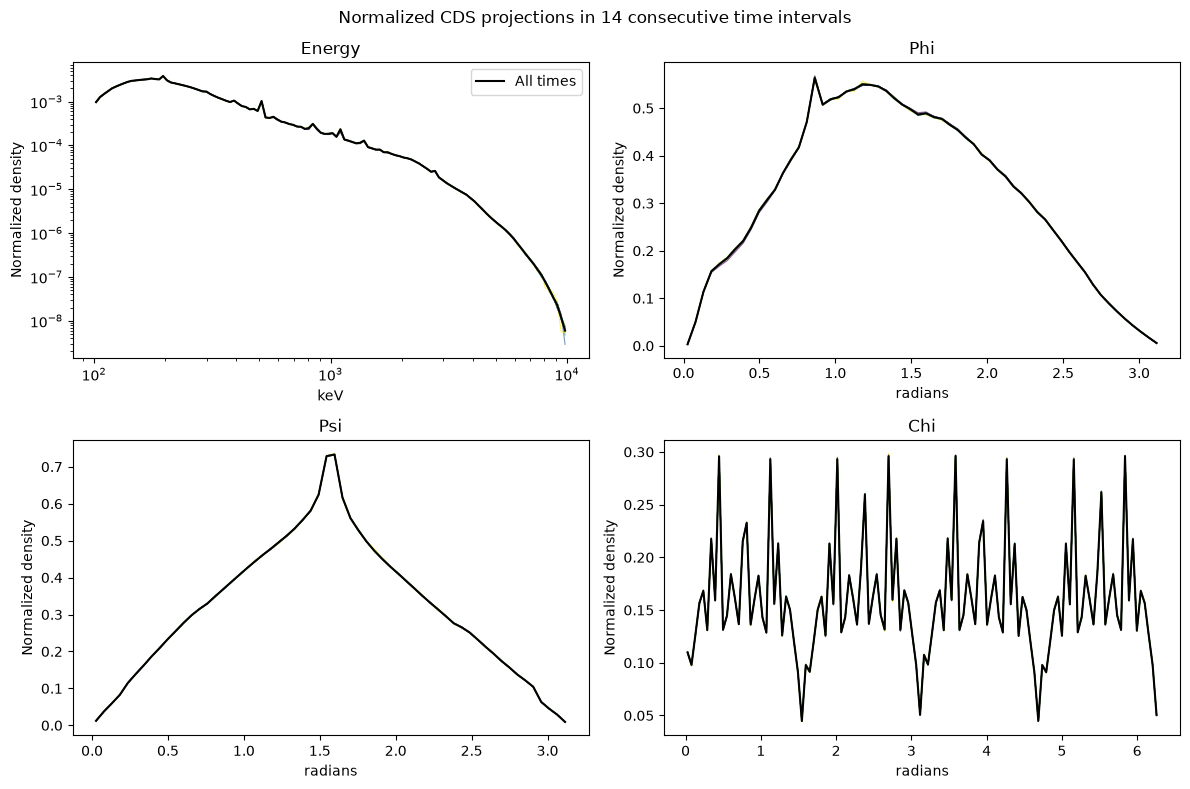

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = plt.cm.viridis(np.linspace(0, 1, number_time_groups))
for ax, (name, edges) in zip(axes.flat, projection_edges.items()):
    centers = np.sqrt(edges[:-1] * edges[1:]) if name == "Energy" else (edges[:-1] + edges[1:]) / 2
    for group, color in enumerate(colors):
        density = group_counts[name][group] / group_counts[name][group].sum() / np.diff(edges)
        ax.plot(centers, density, color=color, alpha=0.65, linewidth=0.8)
    pooled = group_counts[name].sum(axis=0) / group_counts[name].sum() / np.diff(edges)
    ax.plot(centers, pooled, color="black", linewidth=1.5, label="All times")
    ax.set(title=name, xlabel="keV" if name == "Energy" else "radians", ylabel="Normalized density")
    if name == "Energy":
        ax.set(xscale="log", yscale="log")
axes[0, 0].legend()
fig.suptitle(f"Normalized CDS projections in {number_time_groups} consecutive time intervals")
fig.tight_layout()

### Quantify shape changes

Each time interval is compared with a reference made from all *other* intervals. Total variation distance (TVD) measures the absolute redistribution of probability. `noise_TVD` is the Gaussian multinomial counting-noise scale, calculated analytically rather than from artificial samples. Every histogram cell is retained in this comparison.

With this event count, very small changes can be statistically detectable. TVD gives their size; `TVD/noise_TVD` shows whether counting noise alone is a plausible explanation.

In [18]:
def shape_metrics(counts):
    pooled = counts.sum(axis=0)
    rows = []
    for observed in counts:
        reference_counts = pooled - observed
        reference = reference_counts / reference_counts.sum()
        probability = observed / observed.sum()
        tvd = 0.5 * np.abs(probability - reference).sum()
        variance = reference * (1 - reference) * (1 / observed.sum() + 1 / reference_counts.sum())
        noise_tvd = 0.5 * np.sqrt(2 / np.pi) * np.sqrt(variance).sum()
        rows.append((tvd, noise_tvd, tvd / noise_tvd))
    return pd.DataFrame(rows, columns=["TVD", "noise_TVD", "TVD/noise_TVD"])

In [19]:
metric_tables = {name: shape_metrics(counts) for name, counts in group_counts.items()}
metric_tables["Joint 4D"] = shape_metrics(joint_counts)
long_term_summary = pd.DataFrame({name: {
    "median_TVD": table["TVD"].median(), "max_TVD": table["TVD"].max(),
    "median_TVD/noise": table["TVD/noise_TVD"].median(), "max_TVD/noise": table["TVD/noise_TVD"].max(),
} for name, table in metric_tables.items()}).T
long_term_summary

,median_TVD,max_TVD,median_TVD/noise,max_TVD/noise
Energy,0.002044,0.008398,1.769974,7.614228
Phi,0.001069,0.002572,1.244045,3.035383
Psi,0.000883,0.001934,1.044262,1.180150
Chi,0.001299,0.002655,1.029770,1.306996
Joint 4D,0.006007,0.012846,1.023248,1.634183


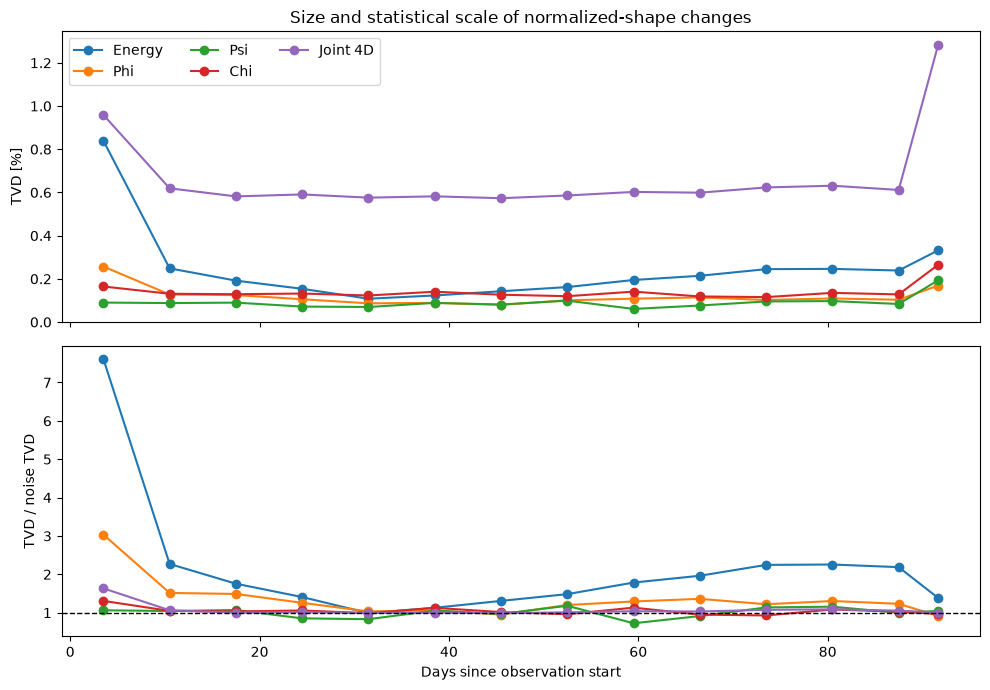

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for name, table in metric_tables.items():
    axes[0].plot(amplitude.midpoint_day, 100 * table["TVD"], marker="o", label=name)
    axes[1].plot(amplitude.midpoint_day, table["TVD/noise_TVD"], marker="o", label=name)
axes[1].axhline(1, color="black", linestyle="--", linewidth=1, label="Counting-noise scale")
axes[0].set(ylabel="TVD [%]", title="Size and statistical scale of normalized-shape changes")
axes[1].set(xlabel="Days since observation start", ylabel="TVD / noise TVD")
axes[0].legend(ncol=3)
fig.tight_layout()

### Where the normalized shape changes

For each time interval, the reference is formed from all other intervals. The heatmaps show $100\,(p_{i,b}-p_{\mathrm{ref},b})$: the difference in normalized probability for CDS bin $b$, expressed in percentage points. This is calculated from histogram copies only. It is not a model residual, and no event or histogram bin is removed.

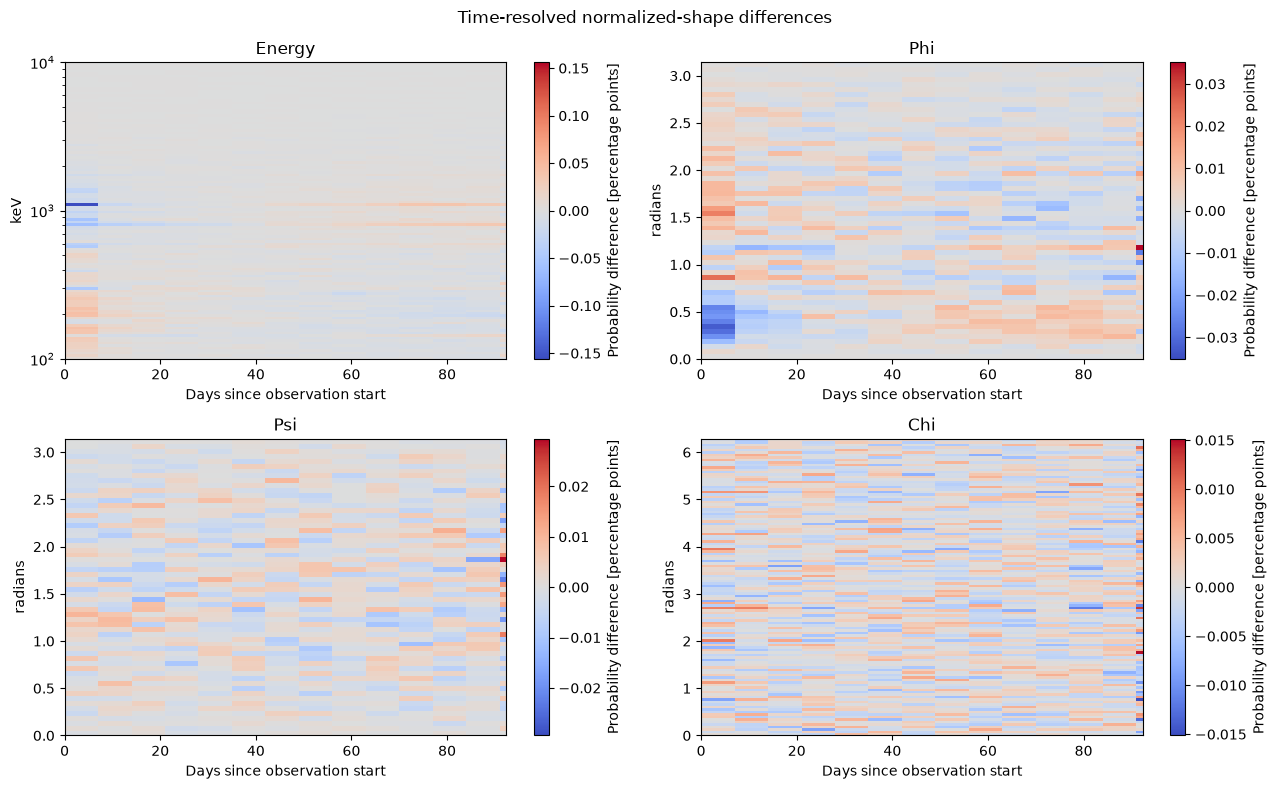

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
elapsed_edges = (time_edges - time_edges[0]) / 86400
for ax, (name, edges) in zip(axes.flat, projection_edges.items()):
    counts = group_counts[name]
    probabilities = counts / counts.sum(axis=1, keepdims=True)
    other_counts = counts.sum(axis=0, keepdims=True) - counts
    references = other_counts / other_counts.sum(axis=1, keepdims=True)
    difference = 100 * (probabilities - references)
    limit = np.max(np.abs(difference))
    image = ax.pcolormesh(elapsed_edges, edges, difference.T, shading="auto", cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.set(title=name, xlabel="Days since observation start", ylabel="keV" if name == "Energy" else "radians")
    if name == "Energy":
        ax.set_yscale("log")
    fig.colorbar(image, ax=ax, label="Probability difference [percentage points]")
fig.suptitle("Time-resolved normalized-shape differences")
fig.tight_layout()

## 8. Shape before and after SAA intervals

The two rows below are normalized independently. This removes the different event totals in the before/after selections.

In [22]:
phase_summary = {}
for name, counts in phase_counts.items():
    probabilities = counts / counts.sum(axis=1, keepdims=True)
    tvd = 0.5 * np.abs(probabilities[0] - probabilities[1]).sum()
    pooled = counts.sum(axis=0) / counts.sum()
    variance = pooled * (1 - pooled) * (1 / counts[0].sum() + 1 / counts[1].sum())
    noise_tvd = 0.5 * np.sqrt(2 / np.pi) * np.sqrt(variance).sum()
    phase_summary[name] = (tvd, noise_tvd, tvd / noise_tvd)
pd.DataFrame(phase_summary, index=["TVD", "noise_TVD", "TVD/noise_TVD"]).T

,TVD,noise_TVD,TVD/noise_TVD
Energy,0.006191,0.001166,5.312008
Phi,0.002736,0.000894,3.061484
Psi,0.002552,0.000895,2.849695
Chi,0.001635,0.001329,1.230530


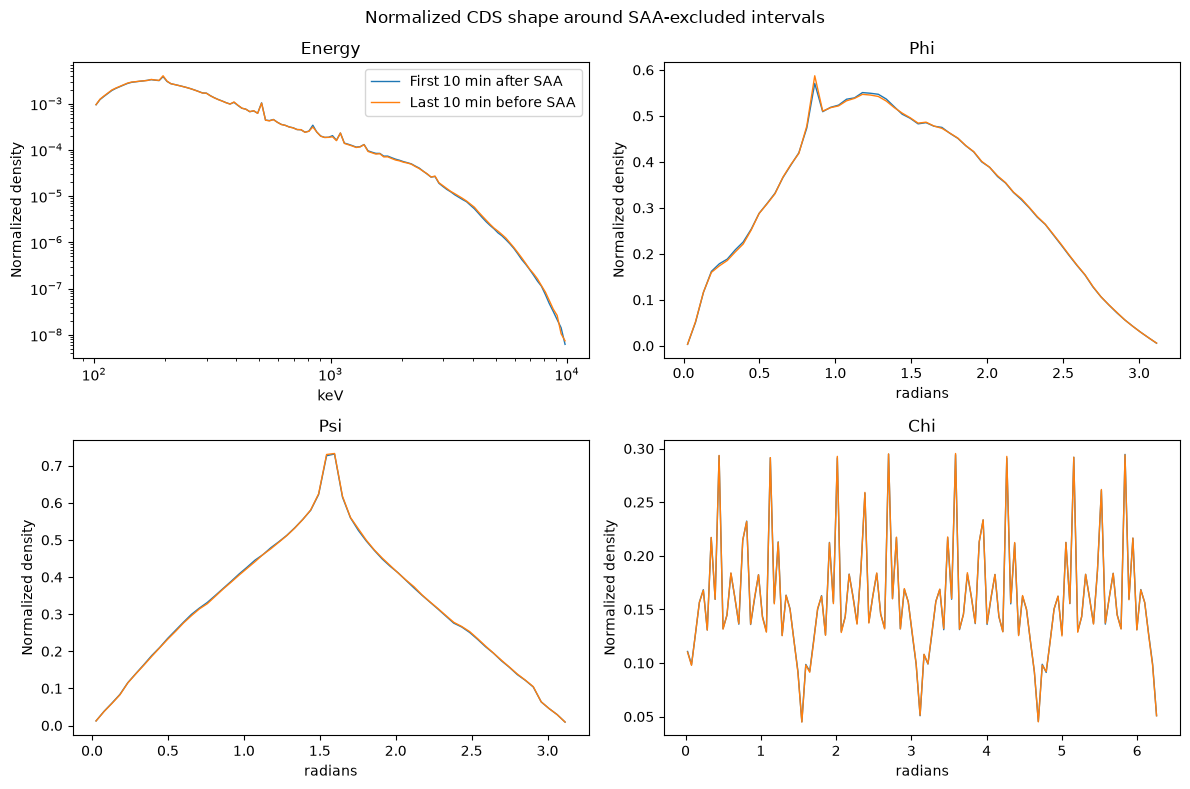

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, edges) in zip(axes.flat, projection_edges.items()):
    centers = np.sqrt(edges[:-1] * edges[1:]) if name == "Energy" else (edges[:-1] + edges[1:]) / 2
    for index, label in enumerate(["First 10 min after SAA", "Last 10 min before SAA"]):
        density = phase_counts[name][index] / phase_counts[name][index].sum() / np.diff(edges)
        ax.plot(centers, density, label=label, linewidth=1)
    ax.set(title=name, xlabel="keV" if name == "Energy" else "radians", ylabel="Normalized density")
    if name == "Energy":
        ax.set(xscale="log", yscale="log")
axes[0, 0].legend()
fig.suptitle("Normalized CDS shape around SAA-excluded intervals")
fig.tight_layout()

## 9. Interpretation and decision

The DC4 file is already almost completely filtered according to the orientation-file SAA definition: only 124 of 168,648,544 events fall in zero-livetime intervals. They are excluded here.

The accepted raw rate is not constant. Across the 7-day groups it rises from about 25.06 to a maximum of about 25.76 events/s before flattening slightly. This is an amplitude result and is kept separate from the normalized-shape test. The final interval is shorter, so its raw TVD can have a larger counting-noise contribution; the `TVD/noise_TVD` panel displays that distinction.

After independent normalization, the shape is **not strictly time independent at the statistical precision of this simulation**:

- The long-term energy projection reaches TVD $\simeq 0.0084$, about 7.6 times its analytic counting-noise scale. `Phi` also exceeds counting noise, though with smaller TVD.
- The coarse joint 4D table reaches TVD $\simeq 0.0128$ and about 1.6 times the counting-noise scale. Its largest absolute TVD includes the shorter final interval, while the noise-scaled result still shows that the comparison is not limited to marginal projections.
- Comparing the 10-minute windows around SAA passages gives TVD/noise ratios of about 5.3 for energy, 3.1 for `Phi`, 2.9 for `Psi`, and 1.2 for `Chi`. Thus some CDS changes are correlated with time since the SAA exclusion.

The effect sizes are small—around one percent or less in the marginal projections and up to about 1.3% in the coarse joint table—but they are resolved by the available event statistics. Therefore the strict factorization $B(x,t)=A(t)P(x)$ is not supported as an exact description of the DC4 simulated background. A time-independent shape may still be an acceptable approximation for a downstream analysis whose systematic-error tolerance is demonstrably larger than these changes, but that tolerance cannot be decided from this notebook alone. A later background model should at minimum consider long-term evolution and time since SAA; this notebook does not construct that model.

In [24]:
export_path = Path("../data/dc4_stability_results.npz")
projection_names = list(projection_edges)
summary_names, summary_columns = list(long_term_summary.index), list(long_term_summary.columns)
export_payload = {
    "schema_version": np.array(1), "source_label": np.array("DC4"),
    "time_interval_days": np.array(time_interval_days), "time_edges": time_edges,
    "midpoint_days": amplitude["midpoint_day"].to_numpy(), "group_days": group_days,
    "group_livetime": group_livetime, "events_per_group": events_per_group,
    "rate_per_second": amplitude["rate_per_second"].to_numpy(),
    "events_per_phase": events_per_phase, "accepted_events": np.array(accepted_events),
    "rejected_events": np.array(rejected_events), "saa_window_seconds": np.array(600),
    "projection_names": np.array(projection_names), "summary_names": np.array(summary_names),
    "summary_columns": np.array(summary_columns),
    "summary_values": long_term_summary.loc[summary_names, summary_columns].to_numpy(),
    "phase_metric_columns": np.array(["TVD", "noise_TVD", "TVD/noise_TVD"]),
    "phase_metric_values": np.array([phase_summary[name] for name in projection_names]),
}
for name in projection_names:
    key, counts, edges = name.lower(), group_counts[name], projection_edges[name]
    probability = counts / counts.sum(axis=1, keepdims=True)
    other_counts = counts.sum(axis=0, keepdims=True) - counts
    reference = other_counts / other_counts.sum(axis=1, keepdims=True)
    phase_probability = phase_counts[name] / phase_counts[name].sum(axis=1, keepdims=True)
    export_payload.update({
        f"{key}_edges": edges, f"{key}_counts": counts, f"{key}_probability": probability,
        f"{key}_density": probability / np.diff(edges), f"{key}_difference_pp": 100 * (probability - reference),
        f"{key}_tvd": metric_tables[name]["TVD"].to_numpy(), f"{key}_noise_tvd": metric_tables[name]["noise_TVD"].to_numpy(),
        f"{key}_tvd_noise_ratio": metric_tables[name]["TVD/noise_TVD"].to_numpy(),
        f"{key}_phase_counts": phase_counts[name], f"{key}_phase_probability": phase_probability,
        f"{key}_phase_difference_pp": 100 * (phase_probability[0] - phase_probability[1]),
    })
joint_probability = joint_counts / joint_counts.sum(axis=1, keepdims=True)
joint_other = joint_counts.sum(axis=0, keepdims=True) - joint_counts
export_payload.update({
    "joint_counts": joint_counts, "joint_probability": joint_probability,
    "joint_difference_pp": 100 * (joint_probability - joint_other / joint_other.sum(axis=1, keepdims=True)),
    "joint_tvd": metric_tables["Joint 4D"]["TVD"].to_numpy(),
    "joint_noise_tvd": metric_tables["Joint 4D"]["noise_TVD"].to_numpy(),
    "joint_tvd_noise_ratio": metric_tables["Joint 4D"]["TVD/noise_TVD"].to_numpy(),
})
np.savez_compressed(export_path, **export_payload)
print(f"Saved {export_path} ({export_path.stat().st_size / 1e6:.2f} MB)")

Saved ../data/dc4_stability_results.npz (1.00 MB)
